# Pooled Calibration Example - Calibration of PTW for Copper Flyer Data using an Emulator
In this script, we demonstrate two ways to implement IMPALA calibration of flyer data using emulators: (1) with a neural net emulator via ModelF and (2) with a bassPCA emulator via ModelBassPca_func. Note that this script contains packages that are not in the dependency list of impala. This code was run using llvmlite=0.45.1, numba=0.62.1, numpy=2.3.5, scikit-learn=3.1.2, skl2onnx=1.20.0, onnxruntime=1.23.2

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyBASS as pb
import fdasrsf as fs
from scipy.interpolate import interp1d
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from numba import njit
from numpy import ndarray
from numpy.typing import ArrayLike

import os
import re

import impala.superCal.post_process as pp
from impala import superCal as sc
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort

# https://github.com/lanl/pyBASS

## Read in and Visualize Data and Simulations

Here, we read in the experimental and simulated flyer plate data. 

In [4]:
datafolder = os.getcwd() + "/../data/Cu"
FILES = np.asarray(os.listdir(datafolder + '/cu_flyer_training/'))
FILES = FILES[np.where(np.asarray(FILES) != '.DS_Store')[0]]
temp = np.hstack([re.sub("cu_", "", FILES[i]) for i in range(len(FILES))])
temp = temp.astype('int32')
FILES_REORDER = [ FILES[np.argsort(temp)[i]] for i in range(len(temp))]
flyer_sims = []
for i in range(len(FILES_REORDER)):
    temp = re.sub("cu_", "", FILES_REORDER[i])
    results = pd.read_csv(datafolder + '/cu_flyer_training/' + FILES_REORDER[i] + '/flyer_cu_ses_ptw_'+ str(temp) +'.mat.ult', sep= r"\s+", engine = 'python', skiprows = 2, header = None);
    results = pd.DataFrame(np.asarray(results), columns = ['Time','velocity'])
    results['velocity'] = 10000*results['velocity']
    results[results<0] = 0
    results['run_num'] = temp
    if i == 0:
        flyer_sims = [results]
    else:
        flyer_sims.append(results)


params = pd.read_csv(datafolder + '/flyer_lhs.csv', sep = ",", engine = 'python');

flyer_sims_long = pd.concat(flyer_sims)

flyer_obs = pd.read_csv(datafolder + '/Cu-Flyer/Cu-Cu_Thomas_PTW_PlateImpact/' + 'ofhc-cu-symmetric-impact.txt', sep= r"\s+", engine = 'python', skiprows = 5, header = None);
flyer_obs = pd.DataFrame(np.asarray(flyer_obs), columns = ['Time','velocity'])
flyer_obs_raw = flyer_obs
flyer_obs = flyer_obs[flyer_obs['Time'] > 0.83]

Let's visualize the data and simulations:

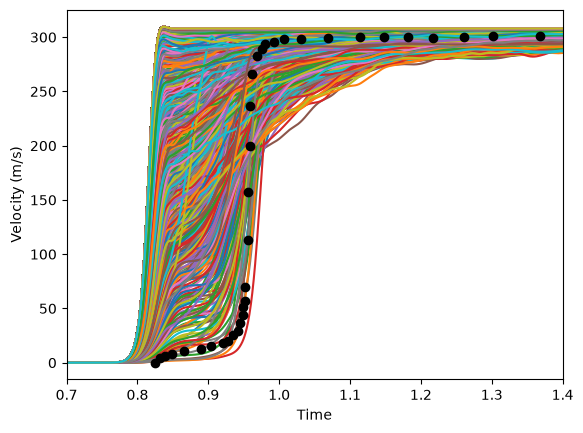

In [5]:
for i in np.arange(0,1000,1):
    plt.plot(flyer_sims[i]['Time'], flyer_sims[i]['velocity'], zorder = 0)#, c = 'gray', zorder = 0)
plt.scatter(flyer_obs_raw['Time'], flyer_obs_raw['velocity'], c = 'black')
plt.xlim(0.7,1.4)
plt.xlabel('Time')
plt.ylabel('Velocity (m/s)')
plt.show()


Now, we interpolate the osberved data and each simulated flyer velocity curve to a shared set of x-axis times. This is helpful later on in warping simulations toward data. 

In [6]:

time_grid = np.arange(0.5,1.4,(1.4-0.7)/500) #initial grid of times to interpolate 
flyer_sims_interp_wide = np.zeros([len(flyer_sims),len(time_grid)])
flyer_sims_interp = []
for i in range(len(flyer_sims)):
    results = pd.DataFrame(np.append(time_grid.reshape(-1,1),np.exp(interp1d(flyer_sims[i]['Time'], np.log(flyer_sims[i]['velocity']+1e-9), kind="linear", fill_value='extrapolate')(time_grid)).reshape(-1,1), axis = 1), 
                           columns = ['Time', 'velocity'])
    results[results<0] = 0
    flyer_sims_interp_wide[i,:] = np.asarray(results['velocity'])
    if i == 0:
        flyer_sims_interp = [results]
    else:
        flyer_sims_interp.append(results)
  
        
flyer_obs_interp = pd.DataFrame(np.append(time_grid.reshape(-1,1),np.exp(interp1d(flyer_obs['Time'], np.log(flyer_obs['velocity']+1e-9), kind="linear", fill_value='extrapolate')(time_grid)).reshape(-1,1), axis = 1), 
                           columns = ['Time', 'velocity'])
flyer_obs_interp[flyer_obs_interp<0]=0


## Warp Flyer Plate Simulations to Data
The timing of shocks in flyer plate simulations are not necessarily well-matched with the observed data. To address this systematic difference between simulations and data, we warp each simulated velocity curve to look more like the real data. This step takes a couple minutes. It is evident from the plot that the warped simulations look more like the observed data than un-warped simulations.

In [7]:
out = fs.fdawarp(flyer_sims_interp_wide.T, time_grid)
out.multiple_align_functions(np.asarray(flyer_obs_interp['velocity']), parallel=True, lam=.01)
ftilde_train_list = out.fn

Text(0, 0.5, 'Velocity (m/s)')

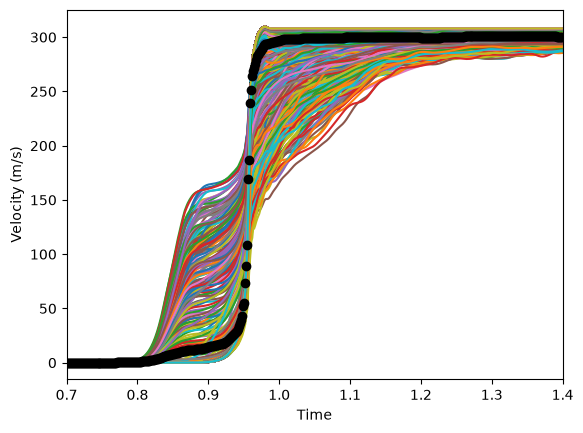

In [8]:

for i in np.arange(0,1000,1):
    plt.plot(time_grid, ftilde_train_list[:,i], zorder = 0)#, c = 'gray', zorder = 0)
plt.scatter(time_grid, flyer_obs_interp.velocity.values, c = 'black')
plt.xlim(0.7,1.4)
plt.xlabel('Time')
plt.ylabel('Velocity (m/s)')


## Fit Emulators 
Now, we fit two kids of emulators. We will focus our modeling efforts on the most interesting region of warped time between 0.8 and 1.1.

In [9]:
sub_inds0 = np.arange(0,len(time_grid),10)
sub_inds = sub_inds0[(time_grid[sub_inds0] > 0.8) * (time_grid[sub_inds0] < 1.1) ]
time_grid2 = time_grid[sub_inds] #reduced time grid we will actually use for calibration. 

First, we fit the BASS PCA emulator. This works by taking the first few principal component of the velocity curves and then modeling the weights associated with those curves as a function of the PTW inputs. We will fit this model for only the subset of times we will include in our calibration later on. 

In [10]:
fit_bass = pb.bassPCA(xx=np.array(params), y = ftilde_train_list.T[:,sub_inds], npc = 20) #this is using a very large number of components to fit data well here. 
preds_bass = fit_bass.predict(np.array(params)).mean(axis=0)

Starting bassPCA with 20 components, using 1 cores.
BASS MCMC Complete. Time: 4.586956 seconds.
BASS MCMC Complete. Time: 4.719937 seconds.
BASS MCMC Complete. Time: 4.722673 seconds.
BASS MCMC Complete. Time: 5.505861 seconds.
BASS MCMC Complete. Time: 4.599205 seconds.
BASS MCMC Complete. Time: 5.007573 seconds.
BASS MCMC Complete. Time: 4.610911 seconds.
BASS MCMC Complete. Time: 4.629516 seconds.
BASS MCMC Complete. Time: 4.729517 seconds.
BASS MCMC Complete. Time: 4.735098 seconds.
BASS MCMC Complete. Time: 4.694228 seconds.
BASS MCMC Complete. Time: 4.543448 seconds.
BASS MCMC Complete. Time: 4.577462 seconds.
BASS MCMC Complete. Time: 4.955333 seconds.
BASS MCMC Complete. Time: 4.884297 seconds.
BASS MCMC Complete. Time: 4.210751 seconds.
BASS MCMC Complete. Time: 3.557211 seconds.
BASS MCMC Complete. Time: 3.662426 seconds.
BASS MCMC Complete. Time: 4.227506 seconds.
BASS MCMC Complete. Time: 4.123957 seconds.


For these simulations, the BASS emulator is not performing well. But, we will keep it around just to demonstrate the IMPALA functionality. 

Text(0.5, 1.0, 'Prediction Accuracy for BASS Model')

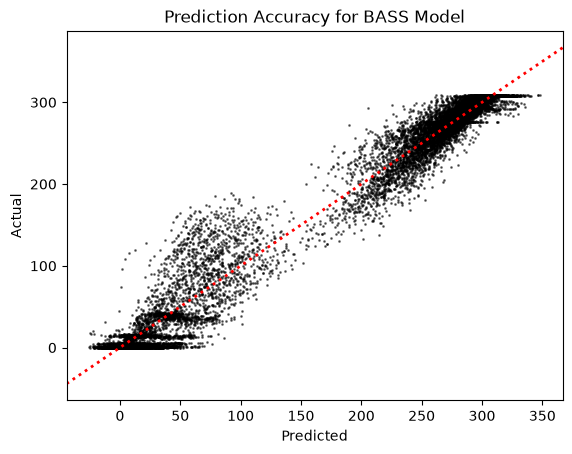

In [11]:
plt.scatter(preds_bass.flatten(),ftilde_train_list.T[:,sub_inds].flatten(), s = 1, c = 'black', alpha = 0.5)
lims = plt.xlim()
plt.plot(lims, lims, 'r:', linewidth=2)
plt.xlim(lims)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title('Prediction Accuracy for BASS Model')


Now, we fit the neural net emulator. This takes about 5 mins. There are lots of packages to do this, but we are going to use sklearn because it is very simple to set up. 

In [12]:
### Reorganize simulations into long data format
input_names = ['theta', 'p','s0','sInf','kappa','lgamma','y0','yInf','y1','y2']
flyer_sims_long_emu = []
for i in range(ftilde_train_list.shape[1]):
    results = pd.DataFrame(np.append(np.append(time_grid.reshape(-1,1),ftilde_train_list[:,i].reshape(-1,1), axis = 1), np.repeat(np.asarray(params)[i,:].reshape(1,-1),len(time_grid), axis = 0),axis=1), 
                           columns = ['time', 'velocity']+input_names)
    if i == 0:
        flyer_sims_long_emu = [results]
    else:
        flyer_sims_long_emu.append(results)
    
flyer_sims_long_emu = pd.concat(flyer_sims_long_emu)
flyer_sims_long_emu = flyer_sims_long_emu.loc[flyer_sims_long_emu.time.values > 0.8]
flyer_sims_long_emu = flyer_sims_long_emu.loc[flyer_sims_long_emu.time.values < 1.1]


### Fit neural net emulator
np.random.seed(0)
nn_emulator = Pipeline(
    [
        # First scale input; this is crucial.
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPRegressor(loss='squared_error',hidden_layer_sizes=(128, 64, 32, 16, 8, 4, 2), batch_size=128, activation="tanh"),
        ),
    ]
)
emu_X = flyer_sims_long_emu[["time"]+ input_names]
emu_y = flyer_sims_long_emu['velocity']
nn_emulator.fit(emu_X.values, emu_y.values)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](11,)","[0.95,0.1 ,2.47,...,0.02,0.29,2.59]"


Optionally, we recommend converting a sklearn emulator to onnx format for a big boost in calibration speed. We provide code for either option below. 

In [13]:
nn_onnx = convert_sklearn(nn_emulator, initial_types=[('float_input', FloatTensorType([None, 11]))])
nn_session = ort.InferenceSession(nn_onnx.SerializeToString(), providers=["CPUExecutionProvider"])

Below, we plot predicted vs observed. Clearly, this predicts the simulations much better than the BASS model. However, we recommend doing additional checks to make sure that the model is predicting well out of sample, too. We did not do this here. 

Text(0.5, 1.0, 'Prediction Accuracy for Neural Net Model')

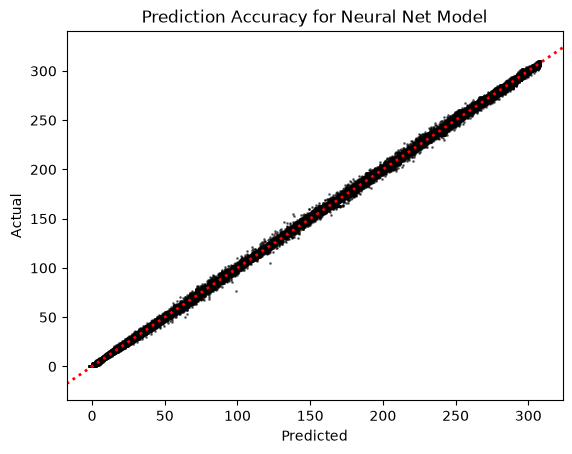

In [14]:
preds_nn = nn_session.run(None, {nn_session.get_inputs()[0].name: np.array(emu_X.values).astype(np.float32)})

plt.scatter(preds_nn,emu_y.values, s = 1, c = 'black', alpha = 0.5)
lims = plt.xlim()
plt.plot(lims, lims, 'r:', linewidth=2)
plt.xlim(lims)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title('Prediction Accuracy for Neural Net Model')


## Model Definitions
Now, we define the emulator in three different ways: (1) using BASS PCA model fit_bass, (2) using sklearn neural net emulator, and (3) using onnx format sklearn neural net emulator. 

In [15]:
# bounds on PTW input parameters to calibrate
bounds_ptw = {    
    'theta' : (0.001,   0.2),    
    'p'     : (0,   5.),   
    's0'    : (0.0001,   0.1),   
    'sInf'  : (0.0001,   0.1),    
    'kappa' : (0.01,   0.5),    
    'lgamma': (-18.,     -1.),    
    'y0'    : (0.00001,   0.1),    
    'yInf'  : (0.00001,   0.1),    
    'y1'    : (0.001,    0.5), 
    'y2'    : (0.281,      5.),  #y2 has to be at least beta  
 }

consts_ptw = {          
  'beta'   : 0.25,            # PTW parameter. The Overdriven Shock Exponent
 'alpha'  : 0.28,            # Thermal Softening of Shear Modulus
   }
# constraints: sInf < s0, yInf < y0, y0 < s0, yInf < sInf, s0 < y1, beta < y2 (but beta is fixed)
# see sc.constraints_ptw()

In [16]:
@njit
def repeat_cols(vec: ndarray, n: int) -> ndarray:
    return vec.repeat(n).reshape(-1, n)

@njit
def repeat_rows(vec: ArrayLike, n: int) -> ndarray:
    return repeat_cols(vec, n).T

@njit
def combine_theta_with_covariates(X: ArrayLike, theta: ArrayLike) -> ndarray:
    return np.column_stack((X, repeat_rows(theta, X.size)))

In [18]:
### Note: for ModelF hierarchical and clustered calibrations, need to specify exp_ind argument. We just include this for demonstration here
s2_inds = np.array([0]*len(sub_inds))

### BASS PCA emulator 
model_bass = sc.ModelBassPca_func(fit_bass, input_names = input_names, exp_ind=s2_inds)
model_bass.constants = consts_ptw

### sklearn Neural Net 
def NN_emu_sklearn(parmat_array):
    if len(parmat_array.shape) == 1:
        parmat_array = np.array(parmat_array).reshape(1,-1)
    inputs = np.vstack([combine_theta_with_covariates(time_grid2.flatten(), t) for t in parmat_array])  # (K, N_ell, P+1)
    res = nn_emulator.predict(inputs)
    res = res.reshape(parmat_array.shape[0], len(time_grid2))
    return res

model_sklearn_nn = sc.ModelF(NN_emu_sklearn, input_names = input_names, exp_ind=s2_inds)
model_sklearn_nn.constants = consts_ptw

### onnx Neural Net
def NN_emu_onnx(parmat_array):
    if len(parmat_array.shape) == 1:
        parmat_array = np.array(parmat_array).reshape(1,-1)
    inputs = np.vstack([combine_theta_with_covariates(time_grid2.flatten(), t) for t in parmat_array])  # (K, N_ell, P+1)
    res = np.array(nn_session.run(None, {nn_session.get_inputs()[0].name: np.array(inputs).astype(np.float32)})).flatten()
    res = res.reshape(parmat_array.shape[0], len(time_grid2))
    return res

model_onnx_nn = sc.ModelF(NN_emu_onnx, input_names = input_names, exp_ind=s2_inds)
model_onnx_nn.constants = consts_ptw



## Pooled Calibrations 
Here, we set up the calibration object and run the calibrations with three emulator formulations. Note that we would generally want to run these algorithms for more than 5K iterations---we are using this small number here for demonstration. 

In [19]:

### The only difference in the following three calls is which emulation model is being specified 

setup_bass = sc.CalibSetup(bounds_ptw, sc.constraints_ptw)
setup_bass.addVecExperiments(yobs=np.asarray(flyer_obs_interp)[:,1].flatten()[sub_inds], #Note: implementing subsampling!!!!
        model=model_bass, 
        sd_est=np.array([50]),  
        s2_df=np.array([15]), 
        s2_ind=[0]*len(sub_inds),  #Note: implementing subsampling!!!!
        theta_ind=[0]*len(sub_inds))  #Note: implementing subsampling!!!!
setup_bass.setTemperatureLadder(1.02**np.arange(50), start_temper=2000) 
setup_bass.setMCMC(nmcmc=5000, decor=100)#, start_tau_theta=-4.)

setup_sklearn_nn = sc.CalibSetup(bounds_ptw, sc.constraints_ptw)
setup_sklearn_nn.addVecExperiments(yobs=np.asarray(flyer_obs_interp)[:,1].flatten()[sub_inds], #Note: implementing subsampling!!!!
        model=model_sklearn_nn, 
        sd_est=np.array([50]),  
        s2_df=np.array([15]), 
        s2_ind=[0]*len(sub_inds),  #Note: implementing subsampling!!!!
        theta_ind=[0]*len(sub_inds))  #Note: implementing subsampling!!!!
setup_sklearn_nn.setTemperatureLadder(1.02**np.arange(50), start_temper=2000) 
setup_sklearn_nn.setMCMC(nmcmc=5000, decor=100)#, start_tau_theta=-4.)


setup_onnx_nn = sc.CalibSetup(bounds_ptw, sc.constraints_ptw)
setup_onnx_nn.addVecExperiments(yobs=np.asarray(flyer_obs_interp)[:,1].flatten()[sub_inds], #Note: implementing subsampling!!!!
        model=model_onnx_nn, 
        sd_est=np.array([50]),  
        s2_df=np.array([15]), 
        s2_ind=[0]*len(sub_inds),  #Note: implementing subsampling!!!!
        theta_ind=[0]*len(sub_inds))  #Note: implementing subsampling!!!!
setup_onnx_nn.setTemperatureLadder(1.02**np.arange(50), start_temper=2000) 
setup_onnx_nn.setMCMC(nmcmc=5000, decor=100)#, start_tau_theta=-4.)




In [20]:
## Takes a few mins
out_bass = sc.calibPool(setup_bass)
out_sklearn_nn = sc.calibPool(setup_sklearn_nn)
out_onnx_nn = sc.calibPool(setup_onnx_nn)



[2026-10-14 13:35:15 | 4999/4999 (100%) | WALL: 0:02:07 | ETA: 0:00:00 | 39.23it/s]
Calibration MCMC Complete. Time: 128.062088 seconds.

[2026-10-14 13:37:19 | 4999/4999 (100%) | WALL: 0:02:01 | ETA: 0:00:00 | 41.02it/s]
Calibration MCMC Complete. Time: 123.195446 seconds.

[2026-10-14 13:38:05 | 4999/4999 (100%) | WALL: 0:00:46 | ETA: 0:00:00 | 107.06it/s]
Calibration MCMC Complete. Time: 46.713897 seconds.


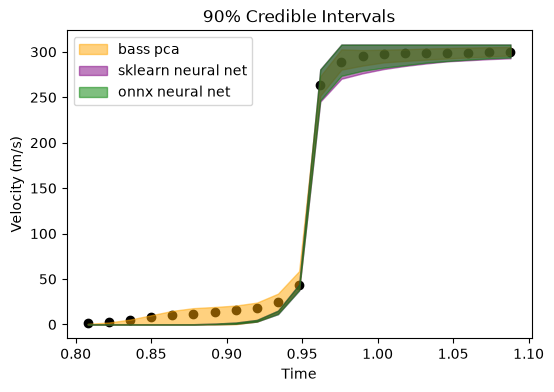

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
mcmc_use = np.arange(2500, 5000, 1)  # burn and thin index

### BASS PCA
mat = np.array(list(out_bass.theta_native.values())).T[mcmc_use]
PARENT_Y = pp.get_outcome_predictions_impala(
    setup_bass,
    theta_input=mat,
)["outcome_draws"]
QUANTS_PARENT_Y = np.quantile(PARENT_Y[0], [0.05, 0.5, 0.95], axis=0)
QUANTS_PARENT_Y[QUANTS_PARENT_Y<0]=0 #BASS PCA model allows negatives
ax.fill_between(
    time_grid2,
    QUANTS_PARENT_Y[0, :],
    QUANTS_PARENT_Y[2, :],
    color="orange",
    zorder=3,
    alpha=0.5,
    label="bass pca",
)

### SKLEARN NN
mat = np.array(list(out_sklearn_nn.theta_native.values())).T[mcmc_use]
PARENT_Y = pp.get_outcome_predictions_impala(
    setup_sklearn_nn,
    theta_input=mat,
)["outcome_draws"]
QUANTS_PARENT_Y = np.quantile(PARENT_Y[0], [0.05, 0.5, 0.95], axis=0)[:,0,:]
ax.fill_between(
    time_grid2,
    QUANTS_PARENT_Y[0, :],
    QUANTS_PARENT_Y[2, :],
    color="purple",
    zorder=3,
    alpha=0.5,
    label="sklearn neural net",
)



### ONNX NN
mat = np.array(list(out_onnx_nn.theta_native.values())).T[mcmc_use]
PARENT_Y = pp.get_outcome_predictions_impala(
    setup_onnx_nn,
    theta_input=mat,
)["outcome_draws"]
QUANTS_PARENT_Y = np.quantile(PARENT_Y[0], [0.05, 0.5, 0.95], axis=0)[:,0,:]
ax.fill_between(
    time_grid2,
    QUANTS_PARENT_Y[0, :],
    QUANTS_PARENT_Y[2, :],
    color="green",
    zorder=3,
    alpha=0.5,
    label="onnx neural net",
)

ax.set_xlabel('Time')
ax.set_ylabel('Velocity (m/s)')
ax.set_title('90% Credible Intervals')
plt.scatter(time_grid2, setup_bass.ys[0], c = 'black')
ax.legend()



## Hierarchical Calibration Demonstration
Just to demonstrate the machinery, suppose that wanted to model the first 10 and last 11 observations as different experiments. To get this to work for the BASS emulators via ModelBassPca_func as the code currently stands, you would need to have two emulators (one for each experiment) and two add_vec_experiments calls. We will just skip this and demonstrate on the onnx ModelF emulator. 

In [22]:
### Note: for ModelF hierarchical and clustered calibrations, need to specify exp_ind argument. We just include this for demonstration here
s2_inds = np.array([0]*10 + [1]*11)

### onnx Neural Net
def NN_emu_onnx(parmat_array):
    if len(parmat_array.shape) == 1:
        parmat_array = np.array(parmat_array).reshape(1,-1)
    inputs = np.vstack([combine_theta_with_covariates(time_grid2.flatten(), t) for t in parmat_array])  # (K, N_ell, P+1)
    res = np.array(nn_session.run(None, {nn_session.get_inputs()[0].name: np.array(inputs).astype(np.float32)})).flatten()
    res = res.reshape(parmat_array.shape[0], len(time_grid2))
    return res

model_onnx_nn = sc.ModelF(NN_emu_onnx, input_names = input_names, exp_ind=s2_inds)
model_onnx_nn.constants = consts_ptw



In [23]:

setup_onnx_nn = sc.CalibSetup(bounds_ptw, sc.constraints_ptw)
setup_onnx_nn.addVecExperiments(yobs=np.asarray(flyer_obs_interp)[:,1].flatten()[sub_inds], #Note: implementing subsampling!!!!
        model=model_onnx_nn, 
        sd_est=np.array([50]*2),  
        s2_df=np.array([15]*2), 
        s2_ind=s2_inds,  #Note: implementing subsampling!!!!
        theta_ind=s2_inds)  #Note: implementing subsampling!!!!
setup_onnx_nn.setTemperatureLadder(1.02**np.arange(50), start_temper=2000) 
setup_onnx_nn.setMCMC(nmcmc=5000, decor=100)#, start_tau_theta=-4.)
setup_onnx_nn.setHierPriors(
    theta0_prior_mean=np.repeat(0.5, setup_onnx_nn.p),  # prior mean for theta_0 values
    theta0_prior_cov=np.eye(setup_onnx_nn.p)
    * 10**2,  # prior covariances for theta_0 values
    Sigma0_prior_df=setup_onnx_nn.p
    + 20,  # degrees of freedom for Inverse Wishart prior for Sigma_0. Generally, larger values indicate greater borrowing across experiments.
    Sigma0_prior_scale=np.eye(setup_onnx_nn.p)
    * 0.1
    ** 2,  # scale for Inverse Wishart prior for Sigma_0. Generally, larger values indicate greater borrowing across experiments.
)



In [25]:
## Takes a few mins
out_onnx_nn = sc.calibHier(setup_onnx_nn)



[2026-10-14 13:42:28 | 4999/4999 (100%) | WALL: 0:03:17 | ETA: 0:00:00 | 25.27it/s]
Calibration MCMC Complete. Time: 198.765618 seconds.


In [26]:
theta_parent_onnx_nn = sc.chol_sample_1per_constraints(
    out_onnx_nn.theta0[:, 0],
    out_onnx_nn.Sigma0[:, 0],
    setup_onnx_nn.checkConstraints,
    setup_onnx_nn.bounds_mat,
    setup_onnx_nn.bounds.keys(),
    setup_onnx_nn.bounds,
    setup_onnx_nn.constants,
)

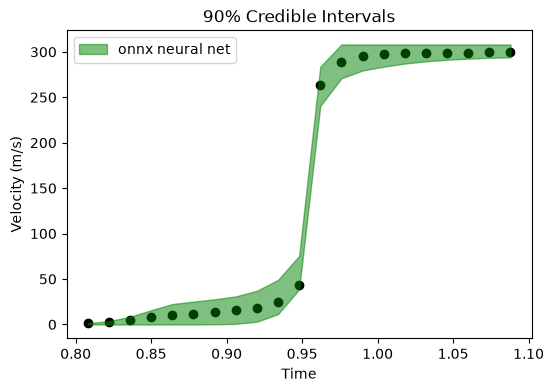

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
mcmc_use = np.arange(2500, 5000, 1)  # burn and thin index

### ONNX NN
mat = np.array(pd.DataFrame(sc.tran_unif(theta_parent_onnx_nn, setup_onnx_nn.bounds_mat, setup_onnx_nn.bounds.keys())))[mcmc_use,:]
PARENT_Y = pp.get_outcome_predictions_impala(
    setup_onnx_nn,
    theta_input=mat,
)["outcome_draws"]
QUANTS_PARENT_Y = np.quantile(PARENT_Y[0], [0.05, 0.5, 0.95], axis=0)[:,0,:]
ax.fill_between(
    time_grid2,
    QUANTS_PARENT_Y[0, :],
    QUANTS_PARENT_Y[2, :],
    color="green",
    zorder=3,
    alpha=0.5,
    label="onnx neural net",
)

ax.set_xlabel('Time')
ax.set_ylabel('Velocity (m/s)')
ax.set_title('90% Credible Intervals')
plt.scatter(time_grid2, setup_bass.ys[0], c = 'black')
ax.legend()

